## Evrişimsel Sinir Ağları ve Streamlit ile Alman Trafik İşaretlerini Tanıma Sistemi

Bu projede, Alman trafik işaretlerini yapay zekâ kullanarak tanıyan bir sistem geliştirilmesi hedeflenmektedir. Proje kapsamında CNN modeli eğitilerek 43 farklı trafik işaretinin sınıflandırılması ve bu modelin bir web uygulamasında kullanılması planlanmaktadır.

In [ ]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D, BatchNormalization, InputLayer, Reshape
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2

import warnings
warnings.filterwarnings('ignore')

In [13]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [14]:
print(os.listdir("/kaggle/input/datasets"))

['meowmeowmeowmeowmeow']


In [15]:
import os

path = "/kaggle/input/datasets/meowmeowmeowmeowmeow"

print(os.listdir(path))


['gtsrb-german-traffic-sign']


In [16]:
import os

path = "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
print(os.listdir(path))

['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv', 'meta', 'test', 'train']


In [18]:
labels = [
    "Speed limit (20 km/h)",
    "Speed limit (30 km/h)",
    "Speed limit (50 km/h)",
    "Speed limit (60 km/h)",
    "Speed limit (70 km/h)",
    "Speed limit (80 km/h)",
    "End of speed limit (80 km/h)",
    "Speed limit (100 km/h)",
    "Speed limit (120 km/h)",
    "No passing",
    "No passing for vehicles over 3.5 tons",
    "Right-of-way at next intersection",
    "Priority road",
    "Yield",
    "Stop",
    "No vehicles",
    "Vehicles over 3.5 tons prohibited",
    "No entry",
    "General caution",
    "Dangerous curve to the left",
    "Dangerous curve to the right",
    "Double curve",
    "Bumpy road",
    "Slippery road",
    "Road narrows on the right",
    "Road work",
    "Traffic signals",
    "Pedestrians",
    "Children crossing",
    "Bicycles crossing",
    "Beware of ice/snow",
    "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead",
    "Turn left ahead",
    "Ahead only",
    "Go straight or right",
    "Go straight or left",
    "Keep right",
    "Keep left",
    "Roundabout mandatory",
    "End of no passing",
    "End of no passing by vehicles over 3.5 tons"
]
img_path = path + '/'

In [20]:
img_list = train_df["Path"].tolist()
label_list = train_df["ClassId"].tolist()

In [21]:
df=pd.DataFrame({'img':img_list , 'label':label_list})

In [22]:
df.head()

,img,label
0,Train/20/00020_00000_00000.png,20
1,Train/20/00020_00000_00001.png,20
2,Train/20/00020_00000_00002.png,20
3,Train/20/00020_00000_00003.png,20
4,Train/20/00020_00000_00004.png,20


In [23]:
df["label_name"] = df["label"].map(lambda x: labels[x])

In [24]:
df.head()

,img,label,label_name
0,Train/20/00020_00000_00000.png,20,Dangerous curve to the right
1,Train/20/00020_00000_00001.png,20,Dangerous curve to the right
2,Train/20/00020_00000_00002.png,20,Dangerous curve to the right
3,Train/20/00020_00000_00003.png,20,Dangerous curve to the right
4,Train/20/00020_00000_00004.png,20,Dangerous curve to the right


In [25]:
test_data = pd.DataFrame({
    "img": test_df["Path"],
    "label": test_df["ClassId"]
})

test_data["label_name"] = test_data["label"].map(lambda x: labels[x])

In [26]:
test_data.head(
    
)

,img,label,label_name
0,Test/00000.png,16,Vehicles over 3.5 tons prohibited
1,Test/00001.png,1,Speed limit (30 km/h)
2,Test/00002.png,38,Keep right
3,Test/00003.png,33,Turn right ahead
4,Test/00004.png,11,Right-of-way at next intersection


In [32]:
from tqdm import tqdm
x_train = []

for img in tqdm(df["img"]):
    img = cv2.imread(os.path.join(path, img))
    img = cv2.resize(img, (32, 32))
    img = (img / 255.0).astype(np.float32)
    x_train.append(img)

x_train = np.array(x_train)

100%|██████████| 39209/39209 [00:37<00:00, 1038.62it/s]


In [38]:
from tqdm import tqdm
x_test = []

for img in tqdm(test_data["img"]):
    image = cv2.imread(path + "/" + img)
    image = cv2.resize(image, (32, 32))
    image = (image / 255.0).astype(np.float32)
    x_test.append(image)

x_test = np.array(x_test)

100%|██████████| 12630/12630 [17:44<00:00, 11.87it/s] 


In [39]:
y = df["label"].values
y_test = test_data["label"].values

In [42]:
model = Sequential()

model.add(Conv2D(32, (3,3), activation='relu',
                 input_shape=(32,32,3),
                 kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(128, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))
model.add(Conv2D(128, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())

model.add(Dense(256, activation='relu',
                kernel_regularizer=l2(0.001)))

model.add(Dropout(0.5))

model.add(Dense(43, activation='softmax'))

In [43]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [44]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 2, 2, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 284,907 (1.09 MB)

 Trainable params: 284,907 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
history_cnn = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    batch_size=64,
    epochs=20,
    verbose=1
)

Epoch 1/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.4030 - loss: 2.1902 - val_accuracy: 0.7483 - val_loss: 1.0373
Epoch 2/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8662 - loss: 0.6888 - val_accuracy: 0.8851 - val_loss: 0.6599
Epoch 3/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9449 - loss: 0.4569 - val_accuracy: 0.9085 - val_loss: 0.6198
Epoch 4/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9635 - loss: 0.3805 - val_accuracy: 0.9146 - val_loss: 0.5825
Epoch 5/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9695 - loss: 0.3428 - val_accuracy: 0.9278 - val_loss: 0.5507
Epoch 6/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9749 - loss: 0.3147 - val_accuracy: 0.9104 - val_loss: 0.5815
Epoch 7/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9769 - loss: 0.2990 - val_accuracy: 0.9395 - val_loss: 0.4629
Epoch 8/20
613/613 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9795 - loss: 0.2802 - val_accuracy: 

In [46]:
test_loss, test_acc = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9503 - loss: 0.3674
Test Loss: 0.36742380261421204
Test Accuracy: 0.9502770900726318


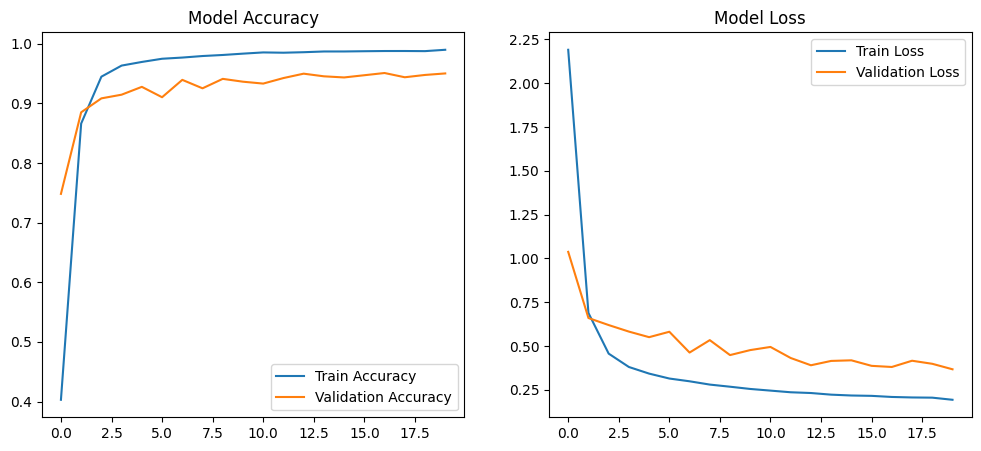

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(history_cnn.history["accuracy"], label="Train Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.title("Model Accuracy")

plt.subplot(1,2,2)
plt.plot(history_cnn.history["loss"], label="Train Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.legend()
plt.title("Model Loss")

plt.show()

In [48]:
model.save("German_Traffic_Sign_CNN.keras")

In [49]:
from sklearn.metrics import classification_report

y_pred = np.argmax(model.predict(x_test), axis=1)

print(classification_report(y_test, y_pred))

395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
              precision    recall  f1-score   support

           0       1.00      0.83      0.91        60
           1       0.97      0.98      0.98       720
           2       0.97      0.99      0.98       750
           3       0.97      0.94      0.95       450
           4       0.99      0.95      0.97       660
           5       0.86      0.95      0.90       630
           6       0.99      0.92      0.96       150
           7       0.97      0.88      0.92       450
           8       0.94      0.98      0.96       450
           9       0.98      1.00      0.99       480
          10       0.99      0.98      0.98       660
          11       0.96      0.96      0.96       420
          12       0.99      0.92      0.95       690
          13       0.98      0.99      0.99       720
          14       1.00      0.99      1.00       270
          15       0.96      0.98      0.97       210
          16       0.97      0.99      0

In [50]:
import os

print(os.path.exists("German_Traffic_Sign_CNN.keras"))

True


In [51]:
meta_path = os.path.join(path, "Meta")

print("Meta içeriği:")
print(os.listdir(meta_path))

Meta içeriği:
['.~lock.ClassesInformation.ods#', '.~lock.ClassesInformationStrong.ods#', '0.png', '1.png', '10.png', '11.png', '12.png', '13.png', '14.png', '15.png', '16.png', '17.png', '18.png', '19.png', '2.png', '20.png', '21.png', '22.png', '23.png', '24.png', '25.png', '26.png', '27.png', '28.png', '29.png', '3.png', '30.png', '31.png', '32.png', '33.png', '34.png', '35.png', '36.png', '37.png', '38.png', '39.png', '4.png', '40.png', '41.png', '42.png', '5.png', '6.png', '7.png', '8.png', '9.png']


In [54]:
meta_images = []

for img in os.listdir(meta_path):
    if img.endswith((".png", ".jpg", ".ppm")):
        meta_images.append(os.path.join(meta_path, img))

print("Meta görsel sayısı:", len(meta_images))

Meta görsel sayısı: 43


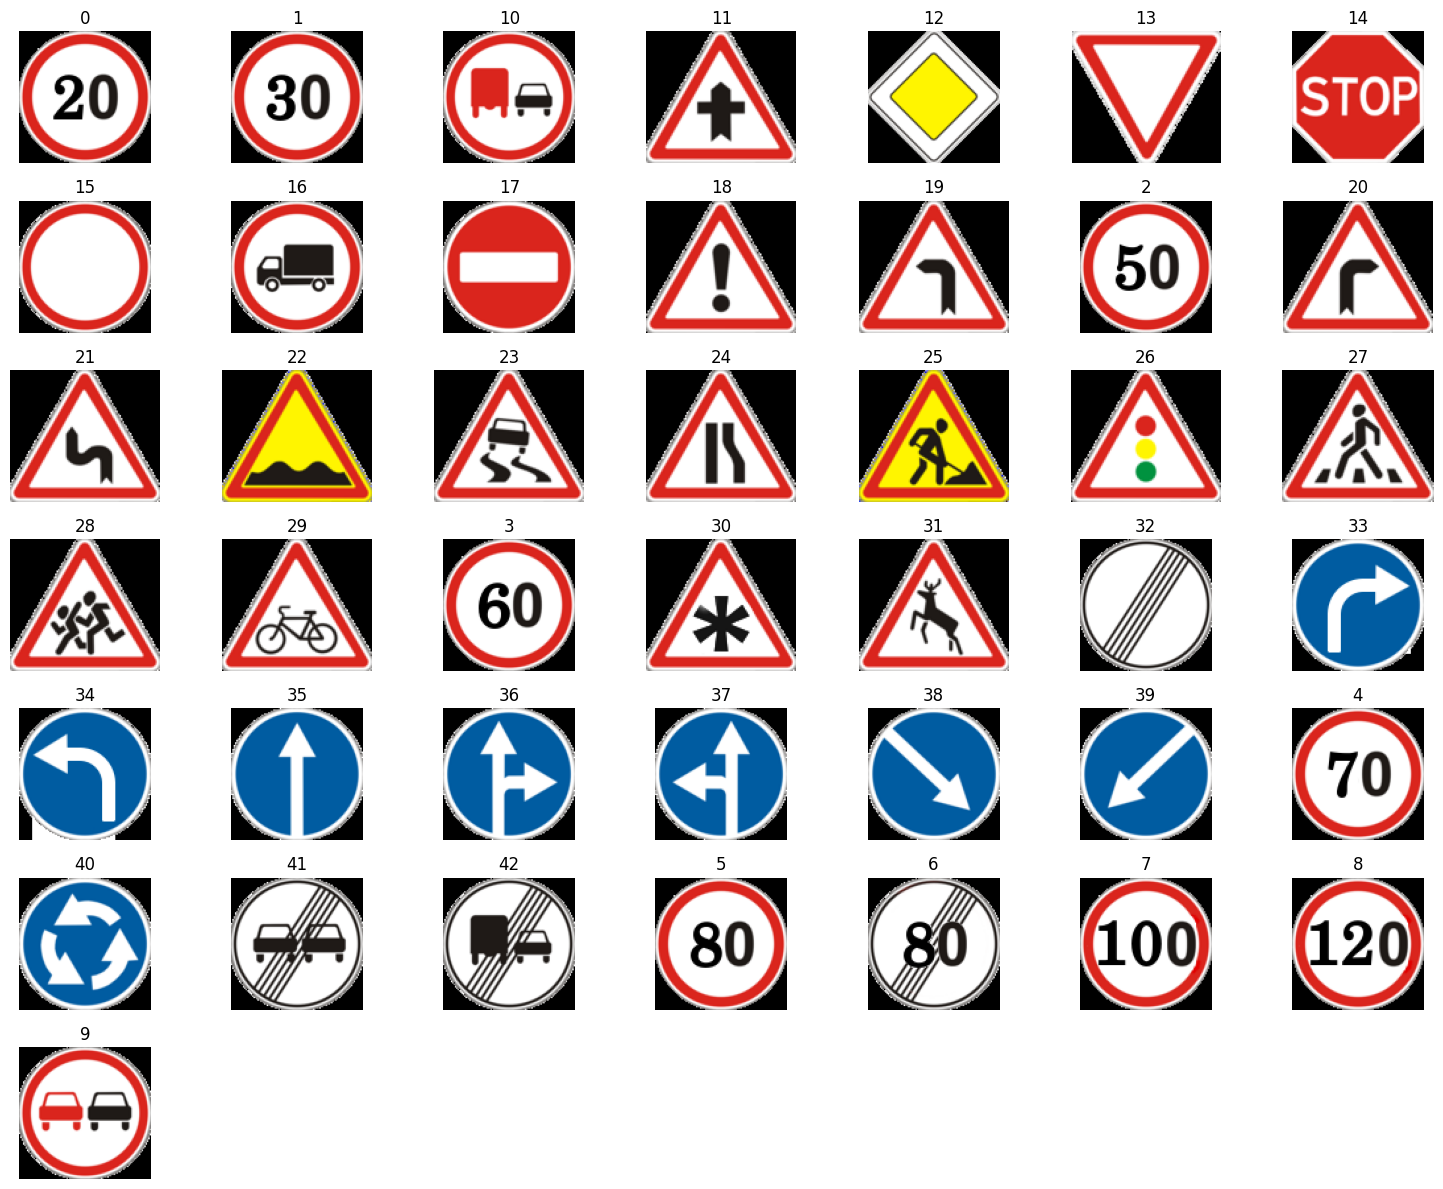

In [55]:
plt.figure(figsize=(15, 12))

for i, img_path in enumerate(meta_images):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(7, 7, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(img_path).split(".")[0])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [56]:
print(len(meta_images))

43


In [57]:
meta_df = pd.read_csv(os.path.join(path, "Meta.csv"))

meta_df.head()

,Path,ClassId,ShapeId,ColorId,SignId
0,Meta/27.png,27,0,0,1.32
1,Meta/0.png,0,1,0,3.29
2,Meta/1.png,1,1,0,3.29
3,Meta/10.png,10,1,0,3.27
4,Meta/11.png,11,0,0,1.22


In [58]:
meta_images = dict(zip(meta_df["ClassId"], meta_df["Path"]))

In [60]:
print(meta_images[14])
print(labels[14])

Meta/14.png
Stop


Proje sonucunda, CNN modeli ile 43 farklı Alman trafik işaretini tanıyabilen bir yapay zekâ sistemi geliştirilmiştir. Model, test verilerinde yaklaşık %95 doğruluk elde etmiş ve Streamlit web uygulamasına entegre edilerek yüklenen trafik işaretlerinin otomatik olarak tahmin edilmesi sağlanmıştır.